#**Assignment #1. OpenCV Tutorial** [![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/YoniChechik/AI_is_Math/blob/master/c_01_intro_to_CV_and_Python/OpenCV_tutorial.ipynb)

OpenCV (Open Source Computer Vision Library) The OpenCV project was initially an Intel Research initiative to advance CPU-intensive applications. Officially launched in 1999. OpenCV is an open source computer vision and machine learning software library. OpenCV was built to provide a common infrastructure for computer vision applications and to accelerate the use of machine perception in the commercial products.
[https://opencv.org/about/]

**Free OpenCV course**: https://opencv.org/university/free-opencv-course/?utm_source=opcv&utm_medium=menu&utm_campaign=obc

**More OpenCV functions**: https://github.com/BhanuPrakashNani/Image_Processing

In [32]:
import cv2  # opencv for python package
import matplotlib.pyplot as plt
import os
import numpy as np

In [33]:
#Mount your google drive
#from google.colab import drive
#drive.mount('/content/drive')

#change the directory
os.chdir('/home/alex930307/CSIE/DL/Assignment 1 Python Platform and Basic Image Processing/images')

### **PartA. Read and Plot an Image**

1. Read and plot an image with OpenCV.

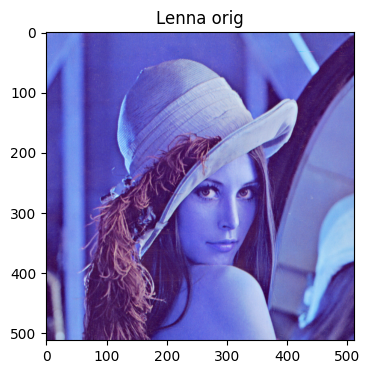

In [34]:
img=cv2.imread("Lenna.png")
plt.figure(figsize=(4,4))
plt.imshow(img)
plt.title("Lenna orig")
plt.show()

We got a weird image colors... This is because OpenCV uses image reading convention of BGR and matplotlib uses RGB.

The fix is easy:




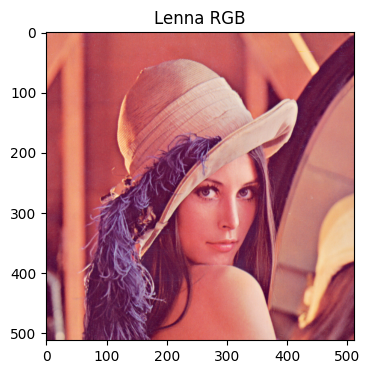

<class 'numpy.ndarray'>
(512, 512, 3)


In [35]:
img=cv2.cvtColor(img,cv2.COLOR_BGR2RGB)
plt.figure(figsize=(4,4))
plt.imshow(img)
plt.title("Lenna RGB")
plt.show()

# some image info:
print(type(img))
print(img.shape)

2. Show the channels of a color image. A color image contains R, G, B channels. Learn to show each channel.

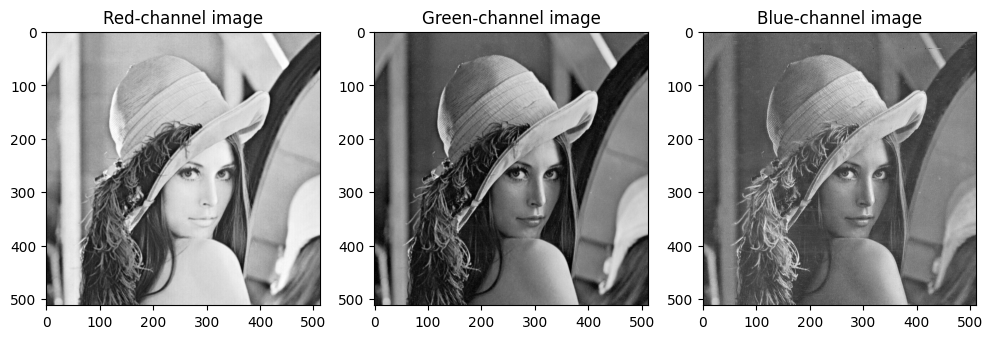

In [36]:
# show the R, G, and B channels
fig,ax_arr=plt.subplots(1,3,figsize=(12,4)) # fig -> the entire figure, ax_arr -> the subplots
ax_arr[0].imshow(img[:,:,0],cmap='gray') 
# ax_arr[0] is the first subplot ,img[:,:,0] is the red channel, cmap set the image to gray
ax_arr[0].set_title("Red-channel image")
ax_arr[1].imshow(img[:,:,1],cmap='gray') # img[:,:,1] is the green channel
ax_arr[1].set_title("Green-channel image")
ax_arr[2].imshow(img[:,:,2],cmap='gray') # img[:,:,2] is the blue channel
ax_arr[2].set_title("Blue-channel image")
plt.show()

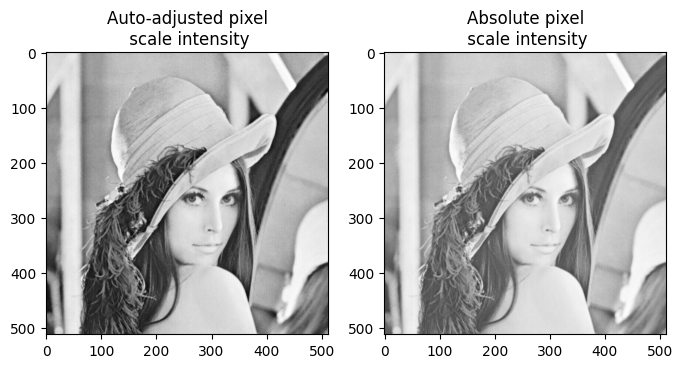

In [ ]:
# gray color-mapping
fig,ax_arr=plt.subplots(1,2,figsize=(8,4))

ax_arr[0].imshow(img[:,:,0], cmap="gray") 
# using the min and max intensity value to auto-adjusted pixel scale intensity, high contrast
ax_arr[0].set_title("Auto-adjusted pixel\n scale intensity")

ax_arr[1].imshow(img[:,:,0], cmap="gray", vmin=0, vmax=255) # using absolute pixel scale intensity, low contrast
ax_arr[1].set_title("Absolute pixel\n scale intensity")
plt.show()

### **Part B. Advanced Image Processing Functions**

1. **Image blurring**. Apply an average filtering to the image.
2. **Edge detection.**. Apply Canny edge decteion to the image.
3. **Circle detection**. Apply Hough transform to the image.


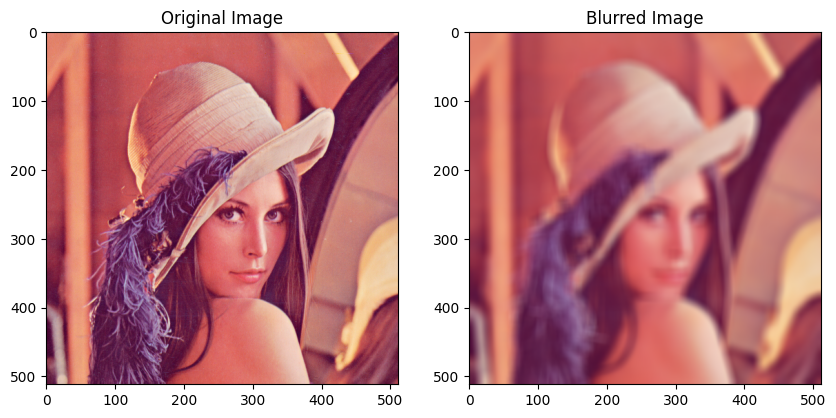

In [38]:
# image blurring
img_blurred=cv2.blur(img,(15,15))  
# use a 15x15 average kernel with square shape to replace each pixel with the average of its 15x15 neighborhood 
fig,ax_arr=plt.subplots(1, 2, figsize=(10,10))
ax_arr[0].imshow(img)
ax_arr[0].set_title("Original Image")
ax_arr[1].imshow(img_blurred)
ax_arr[1].set_title("Blurred Image")
plt.show()

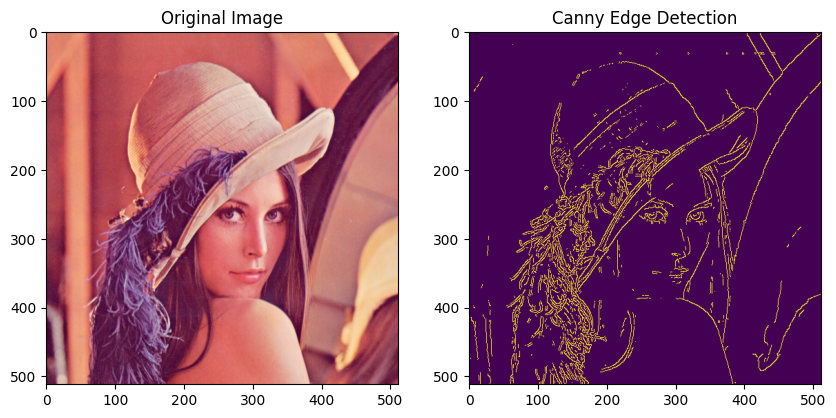

In [39]:
# edge detection
img_canny=cv2.Canny(img,180,200)  # end args are the lower & upper TH of hysteresis
# cv2.Canny(src, threshold1, threshold2), if the gradient is smaller than threshold1, it is considered as not an edge
# if the gradient is larger than threshold2, it is considered as an edge
# if the gradient is between threshold1 and threshold2, it will be considered as an edge only if it is connected to a pixel that is above threshold2
fig,ax_arr=plt.subplots(1, 2, figsize=(10,10))
ax_arr[0].imshow(img)
ax_arr[0].set_title("Original Image")
ax_arr[1].imshow(img_canny)
ax_arr[1].set_title("Canny Edge Detection")
plt.show()

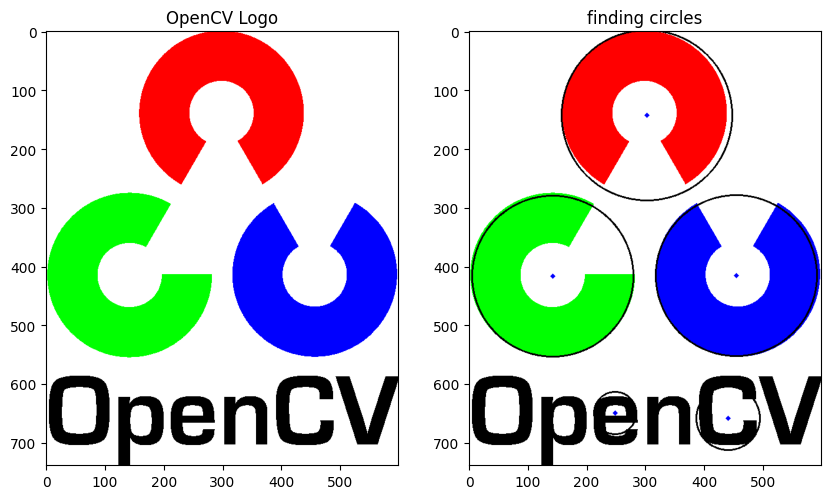

In [40]:
# detect circles
img_logo=cv2.imread("Opencv_logo.png")
img_logo=cv2.cvtColor(img_logo, cv2.COLOR_BGR2RGB)

fig,ax_arr=plt.subplots(1, 2, figsize=(10,10))
ax_arr[0].imshow(img_logo)
ax_arr[0].set_title("OpenCV Logo")

img_gray=cv2.cvtColor(img_logo,cv2.COLOR_RGB2GRAY) # houghCircles only takes gray image
circles=cv2.HoughCircles(img_gray, cv2.HOUGH_GRADIENT, 0.1, 50, param1=50, param2=38)
# use Hough_Gradient as the detection method
# dp is the inverse ratio of the accumulator resolution to the image resolution, here dp=0.1 means the accumulator has 10 times the resolution of the input image
# minDist is the minimum distance between the centers of the detected circles
# param1 is the higher threshold of the two passed to the Canny edge detector (the lower one is twice smaller)
# param2 is the accumulator threshold for the circle centers at the detection stage. The smaller it is, the more false circles may be detected. Circles, corresponding to the larger accumulator values, will be returned first.
for x, y, r in circles[0, :]:
    # draw the outer circle
    cv2.circle(img_logo, (int(x), int(y)), int(r), (0, 0, 0), 2) # cv2.circle(src, (x0, y0), radius, color, thickness)
    # draw the center of the circle
    cv2.circle(img_logo, (int(x), int(y)), 2, (0, 0, 255), 3)

ax_arr[1].imshow(img_logo)
ax_arr[1].set_title("finding circles")
plt.show()

### **Part C. Basic Image Processing Implementation**
Implement the following image processing functions  using CV2 with the aids of Germini.

*   Image thresholding
*   Image histogram



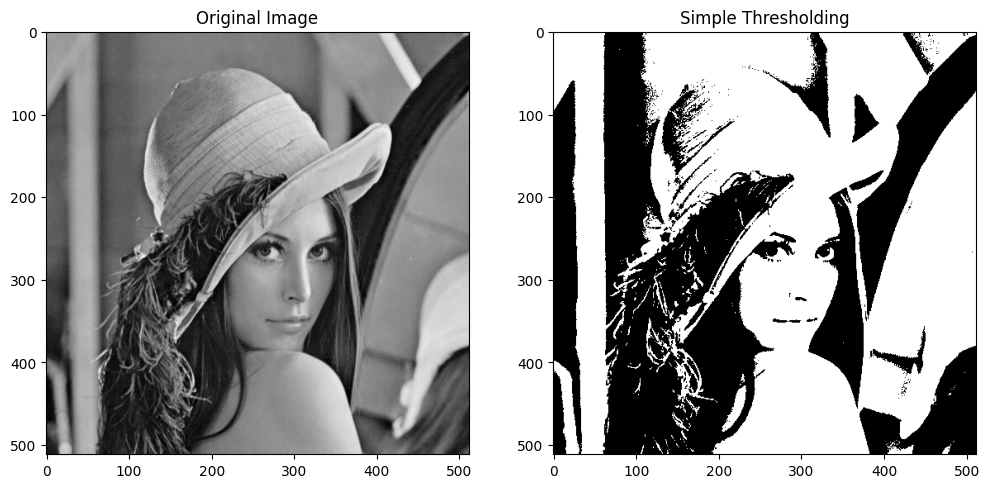

In [41]:
# Image thresholding
img = cv2.imread('Lenna.png', cv2.IMREAD_GRAYSCALE)

# Threshold
ret, thresh = cv2.threshold(img, 127, 255, cv2.THRESH_BINARY)
# cv2.threshold(src, thresh, maxval, type)
# thresh: threshold value
# maxval: value to be given if pixel value is more than (sometimes less than)
# type: thresholding type, here we use simple binary thresholding

# Show images
fig, ax_arr = plt.subplots(1, 2, figsize=(12, 6))
ax_arr[0].imshow(img, cmap='gray')
ax_arr[0].set_title('Original Image')

ax_arr[1].imshow(thresh, cmap='gray')
ax_arr[1].set_title('Simple Thresholding')
plt.show()

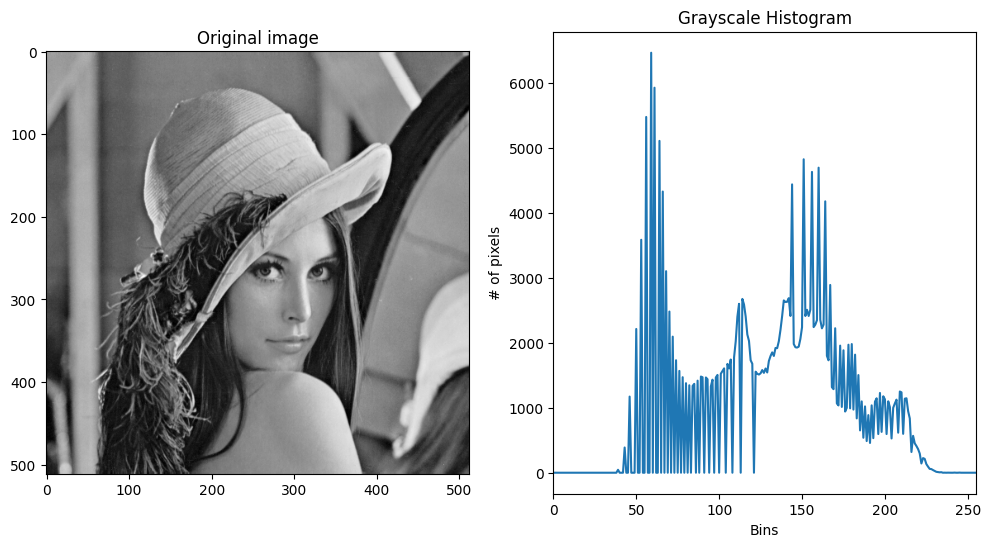

In [42]:
# Image histogram
img = cv2.imread('Lenna.png', cv2.IMREAD_GRAYSCALE)

# calculate histogram
hist = cv2.calcHist([img], [0], None, [256], [0,256])
# cv2.calcHist(images, channels, mask, histSize, ranges)
# use [img] because it expects a list of images
# [0] means gray image's channel
# histSize is the number of bins we want
# ranges is the range of pixel values

fig,ax_arr=plt.subplots(1, 2, figsize=(12,6))

# Show Original image
ax_arr[0].imshow(img, cmap='gray')
ax_arr[0].set_title('Original image')

# Plot Histogram image
ax_arr[1].plot(hist)
ax_arr[1].set_xlim([0, 255]) # set x-axis limits
ax_arr[1].set_xlabel('Bins')
ax_arr[1].set_ylabel('# of pixels')
ax_arr[1].set_title('Grayscale Histogram')
plt.show()